# Preprocess Raw LFP

Prepares the raw hippocampal LFP recordings for position decoding.

- Uses InSeq trials only
- Removes 60 Hz line noise with a notch filter
- Extracts a 500 ms window after each odor onset
- Splits each rat's recording into train, validation and test blocks
- Screens out artifacts and scales each channel using the training data only

**Input:** `data/raw_data/`  
**Output:** `data/processed/raw_lfp/`

## Setup

In [1]:
from collections import Counter
from dataclasses import asdict, dataclass
from pathlib import Path
import csv, json, zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib import format
from scipy.signal import iirnotch, sosfiltfilt, welch, freqz

pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 110

## Paths

All paths are relative to the repository, so the notebook runs from any folder inside it.

In [2]:
# Repository root: the first folder above this notebook that contains pyproject.toml
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())

RAW_ROOT    = REPO / 'data' / 'raw_data'             # one subfolder per rat: <session>_bvr.npz, <session>_lfp.npz
OUTPUT_ROOT = REPO / 'data' / 'processed' / 'raw_lfp'  # one output subfolder per rat
PROFILE     = 'inseq-decoding'                       # InSeq trials only, with the 60 Hz notch
OVERWRITE   = False                                  # refuse to overwrite an existing output folder

SESSIONS = sorted(p.name for p in RAW_ROOT.iterdir() if p.is_dir())
EXAMPLE_SESSION = SESSIONS[0]                        # rat shown in the step-by-step plots

print('Raw data:', RAW_ROOT)
print('Output:  ', OUTPUT_ROOT)
print('Rats:    ', SESSIONS)
print('Example: ', EXAMPLE_SESSION)

Raw data: /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/raw_data
Output:   /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/raw_lfp
Rats:     ['080718_mitt', '081106_barat', '090212_stella', '090212_superchris', '090420_buchanan']
Example:  080718_mitt


## Settings

The same settings are used for every rat.

| Setting | Value | Why |
|---|---|---|
| `window_ms` | 500 | The analysis window after odor onset. Rats usually keep their nose in the port well past 500 ms on InSeq trials, so most trials keep a full window; trials that withdraw earlier are excluded rather than padded. |
| `sample_rate_hz` | 1000 | The recording rate, so 1 sample = 1 ms. |
| `train_fraction`, `validation_fraction` | 0.70, 0.15 | The first 70% of each recording is train, the next 15% validation, the last 15% test. Held-out trials come from later in the session, so no neighboring activity from a training trial ends up in validation or test. |
| `artifact_z` | 20 | A deliberately loose artifact threshold that removes only extreme glitches. At 10, many otherwise clean training trials would be rejected (73 for Mitt, versus 0 at 20). |
| `notch_hz`, `notch_q` | 60, 30 | 60 Hz is US electrical line noise. Q = 30 makes the notch about 2 Hz wide, so nearby brain frequencies are barely affected. |
| `filter_tolerance` | 1e-6 | How far the filter's edge ringing must decay. This sets a guard of about 2.2 s at each edge of a clean block; trials closer to an edge are excluded. |
| `flatline_ms` | 100 | A perfectly flat signal for 100 ms or more indicates a recording dropout, not brain activity. |
| `left_context`, `right_context`, `positive_offset` | 0, 0, 1 | Placeholders for the saved CEBRA sample masks. The CEBRA notebook sets its own context and offset. |

In [3]:
@dataclass(frozen=True)
class Config:
    window_ms: float = 500.0
    sample_rate_hz: float = 1000.0
    train_fraction: float = 0.7
    validation_fraction: float = 0.15
    artifact_z: float = 20.0
    left_context: int = 0
    right_context: int = 0
    positive_offset: int = 1
    profile: str = 'baseline'
    notch_hz: float = 60.0
    notch_q: float = 30.0
    filter_tolerance: float = 1e-6
    flatline_ms: float = 100.0

    def validate(self):
        """Sanity-check settings and return the window length in samples."""
        values = (self.window_ms, self.sample_rate_hz, self.train_fraction,
                  self.validation_fraction, self.artifact_z)
        if not np.isfinite(values).all():
            raise ValueError('Configuration must be finite')
        if self.window_ms <= 0 or self.sample_rate_hz <= 0 or self.artifact_z <= 0:
            raise ValueError('Window, sample rate and artifact threshold must be positive')
        if not 0 < self.train_fraction < 1 or not 0 < self.validation_fraction < 1-self.train_fraction:
            raise ValueError('Split fractions must leave nonempty train/validation/test')
        n = self.window_ms * self.sample_rate_hz / 1000
        if not np.isclose(n, round(n), atol=1e-8) or round(n) < 2:
            raise ValueError('Window must correspond to at least two integer samples')
        for value in (self.left_context, self.right_context, self.positive_offset):
            if not isinstance(value, int):
                raise ValueError('Context and offset must be integers')
        if self.positive_offset == 0:
            raise ValueError('Temporal-positive offset must be nonzero')
        if min(self.left_context, self.right_context) < 0:
            raise ValueError('Context must be nonnegative')
        if self.left_context + self.right_context + abs(self.positive_offset) >= round(n):
            raise ValueError('Context and positive offset leave no eligible centers')
        if self.profile not in ('baseline', 'inseq-decoding'):
            raise ValueError('Profile must be baseline or inseq-decoding')
        if self.profile == 'inseq-decoding':
            if not np.isfinite((self.notch_hz, self.notch_q, self.filter_tolerance, self.flatline_ms)).all():
                raise ValueError('Filter configuration must be finite')
            if not 0 < self.notch_hz < self.sample_rate_hz/2 or self.notch_q <= 0:
                raise ValueError('Notch must be below Nyquist with positive Q')
            if not 0 < self.filter_tolerance < 1 or self.flatline_ms <= 0:
                raise ValueError('Filter tolerance must be in (0,1), flatline duration positive')
        return int(round(n))


cfg = Config(profile=PROFILE)
n_window = cfg.validate()
decoding = cfg.profile == 'inseq-decoding'
print(cfg)
print('window =', n_window, 'samples | notch/InSeq-only profile:', decoding)

Config(window_ms=500.0, sample_rate_hz=1000.0, train_fraction=0.7, validation_fraction=0.15, artifact_z=20.0, left_context=0, right_context=0, positive_offset=1, profile='inseq-decoding', notch_hz=60.0, notch_q=30.0, filter_tolerance=1e-06, flatline_ms=100.0)
window = 500 samples | notch/InSeq-only profile: True


## Reading the raw files

The recordings are large, so these functions read the array shape and channel names without loading the data, and stream one channel at a time.

In [4]:
def header(stream):
    version = format.read_magic(stream)
    readers = {(1, 0): format.read_array_header_1_0, (2, 0): format.read_array_header_2_0}
    if version not in readers:
        raise ValueError(f'Unsupported NPY version {version}')
    shape, fortran, dtype = readers[version](stream)
    if dtype.hasobject or dtype.kind not in 'biuf':
        raise ValueError('Expected real numeric data')
    return shape, fortran, dtype


def metadata(path):
    """Shape/dtype/keys without reading the data."""
    path = Path(path)
    with zipfile.ZipFile(path) as archive:
        with archive.open('data.npy') as stream:
            shape, fortran, dtype = header(stream)
        with archive.open('keys.npy') as stream:
            keys = format.read_array(stream, allow_pickle=False).tolist()
    if len(shape) != 2 or fortran or len(keys) != shape[0] or len(set(keys)) != len(keys):
        raise ValueError(f'Expected C-order channels x samples with unique keys: {path}')
    return dict(path=str(path.resolve()), shape=list(shape), dtype=str(dtype),
                keys=keys, size_bytes=path.stat().st_size)


def rows(path):
    """Yield one row (channel / behavior signal) at a time."""
    with zipfile.ZipFile(path) as archive, archive.open('data.npy') as stream:
        shape, fortran, dtype = header(stream)
        if len(shape) != 2 or fortran:
            raise ValueError('Expected C-order 2-D data')
        size = shape[1] * dtype.itemsize
        for _ in range(shape[0]):
            buf = stream.read(size)
            if len(buf) != size:
                raise ValueError(f'Truncated data: {path}')
            yield np.frombuffer(buf, dtype=dtype)

## Rebuilding trials from behavior

Finds every odor onset and matches it with its nose-poke entry and exit, odor (A–E), sequence position (1–5), InSeq/OutSeq and correct/incorrect labels.
Trials with ambiguous events get an exclusion reason instead of being guessed.

In [5]:
def time_segments(time, expected_hz=1000.0):
    """Split the session into continuous pieces wherever TimeBin jumps."""
    if len(time) < 2 or not np.isfinite(time).all():
        raise ValueError('TimeBin must contain finite timestamps')
    dt = np.diff(time)
    if np.any(dt <= 0):
        raise ValueError('Nonpositive TimeBin step')
    step = 1.0 / expected_hz
    gaps = np.flatnonzero(dt > 1.5 * step)
    regular = dt <= 1.5 * step
    if not regular.any() or not np.allclose(dt[regular], step, rtol=1e-4, atol=1e-8):
        raise ValueError('Inconsistent sample rate within TimeBin segments')
    bounds = np.r_[0, gaps + 1, len(time)]
    return [(int(a), int(b)) for a, b in zip(bounds[:-1], bounds[1:])]   # half-open [a, b)


def reconstruct(time, events, expected_hz=1000.0):
    """events maps names to {raw_index: nonzero_value}; retain every odor onset."""
    segments = time_segments(time, expected_hz)
    onsets = sorted(set().union(*(events[f'Odor{i}'] for i in range(1, 6))))
    transitions = sorted(events['PokeEvents'].items())

    # --- pair poke-in (+1) with poke-out (-1) inside each segment -----------------
    brackets, anomalies = [], []
    for lo, hi in segments:
        active, bad = None, False
        for index, value in transitions:
            if not lo <= index < hi:
                continue
            if value == 1:
                if active is not None:
                    anomalies.append(dict(index=index, reason='repeated_entry'))
                    bad = True
                else:
                    active, bad = index, False
            elif value == -1:
                if active is None:
                    anomalies.append(dict(index=index, reason='unmatched_exit'))
                else:
                    brackets.append((active, index, bad))
                    active = None
            else:
                anomalies.append(dict(index=index, reason='invalid_poke_value'))
                if active is not None:
                    bad = True
        if active is not None:
            anomalies.append(dict(index=active, reason='unmatched_entry'))

    # --- one trial per odor onset -------------------------------------------------
    trials = []
    for trial_id, onset in enumerate(onsets):
        reasons = []
        odors = [(i, events[f'Odor{i+1}'][onset]) for i in range(5) if onset in events[f'Odor{i+1}']]
        positions = [(i, events[f'Position{i+1}'][onset]) for i in range(5) if onset in events[f'Position{i+1}']]
        odor = odors[0][0] if len(odors) == 1 else -1
        position = positions[0][0] if len(positions) == 1 else -1
        if len(odors) != 1 or any(v != 1 for _, v in odors):
            reasons.append('ambiguous_odor')
        if len(positions) != 1 or any(v != 1 for _, v in positions):
            reasons.append('ambiguous_position')
        if any(onset-1 in events[f'Odor{i+1}'] or onset+1 in events[f'Odor{i+1}'] for i, _ in odors):
            reasons.append('odor_not_single_sample_pulse')
        status = [events[k].get(onset, 0) for k in ('InSeqLog', 'PerformanceLog')]
        if any(v not in (-1, 1) for v in status):
            reasons.append('invalid_status')
        matching = [(a, b, bad) for a, b, bad in brackets if a <= onset < b]
        entry = exit_ = None
        if len(matching) != 1:
            reasons.append('missing_poke_bracket')
        else:
            entry, exit_, bad = matching[0]
            if bad:
                reasons.append('ambiguous_poke_bracket')
            if sum(entry <= k < exit_ for k in onsets) != 1:
                reasons.append('multiple_onsets_in_poke')
        segment = next(i for i, (a, b) in enumerate(segments) if a <= onset < b)
        trials.append(dict(trial_id=trial_id, onset=onset, onset_s=float(time[onset]), odor=odor,
                           position=position, inseq_raw=status[0], correct_raw=status[1],
                           inseq=int(status[0] == 1), correct=int(status[1] == 1), poke_in=entry,
                           poke_out=exit_, poke_in_s=None if entry is None else float(time[entry]),
                           poke_out_s=None if exit_ is None else float(time[exit_]),
                           sampling_duration_ms=None if exit_ is None else (exit_-onset)*1000/expected_hz,
                           segment=segment, odor_offset_s=None, reasons=reasons))
    return trials, segments, anomalies


def load_behavior(path, expected_hz=1000.0):
    """Stream the behavior file, keep only nonzero event samples, then reconstruct trials."""
    meta = metadata(path)
    required = ['TimeBin', 'PokeEvents', 'InSeqLog', 'PerformanceLog'] + [
        f'{kind}{i}' for kind in ('Odor', 'Position') for i in range(1, 6)]
    if not set(required) <= set(meta['keys']):
        raise ValueError('Missing required behavior rows')
    events, time, movement = {}, None, {}
    for key, row in zip(meta['keys'], rows(path)):
        if key == 'TimeBin':
            time = row.copy()
        elif key in required or 'Reward' in key:
            if not np.isfinite(row).all():
                raise ValueError(f'Nonfinite behavioral events: {key}')
            ids = np.flatnonzero(row)
            events[key] = dict(zip(ids.tolist(), row[ids].tolist()))   # sparse: {sample: value}
    trials, segments, anomalies = reconstruct(time, events, expected_hz)
    ids = [t['onset'] for t in trials]
    for key, row in zip(meta['keys'], rows(path)):          # second pass: X/Y at each onset
        if key in ('XvalRatMazePosition', 'YvalRatMazePosition'):
            movement[key] = row[ids]
    for i, trial in enumerate(trials):
        for key, values in movement.items():
            trial[key] = float(values[i])
        a, b = trial['poke_in'], trial['poke_out']
        trial['reward_indices_during_poke'] = {key: [] if a is None else [k for k in values if a <= k <= b]
                                             for key, values in events.items() if 'Reward' in key}
    return time, trials, segments, anomalies, meta, events

In [6]:
# Quick check on the example rat: file sizes, channels and the trials found
example_bvr = RAW_ROOT / EXAMPLE_SESSION / f'{EXAMPLE_SESSION}_bvr.npz'
example_lfp = RAW_ROOT / EXAMPLE_SESSION / f'{EXAMPLE_SESSION}_lfp.npz'
for name, m in (('behavior', metadata(example_bvr)), ('LFP', metadata(example_lfp))):
    print(f"{name:9s} shape={m['shape']} dtype={m['dtype']}  ({m['size_bytes']/1e6:.0f} MB on disk)")

time, trials, segments, anomalies, _, _ = load_behavior(example_bvr, cfg.sample_rate_hz)
print(f'\n{len(time):,} samples in {len(segments)} continuous segment(s)')
print(f'{len(trials)} odor onsets found. Poke anomalies: {Counter(a["reason"] for a in anomalies) or "none"}')
trial_df = pd.DataFrame(trials)
print(pd.crosstab(trial_df['inseq'].map({1: 'InSeq', 0: 'OutSeq'}),
                  trial_df['correct'].map({1: 'correct', 0: 'incorrect'})))

behavior  shape=[18, 5255152] dtype=float64  (14 MB on disk)
LFP       shape=[22, 5255152] dtype=float64  (213 MB on disk)



5,255,152 samples in 3 continuous segment(s)
292 odor onsets found. Poke anomalies: none
correct  correct  incorrect
inseq                      
InSeq        230         32
OutSeq        16         14


## Train / validation / test split

Each rat's recording is cut into contiguous time blocks: first 70% train, next 15% validation, last 15% test.
A trial whose 500 ms window crosses a block boundary, a recording break, or the rat's poke exit is excluded.

**Why time blocks instead of random trials:** neighboring trials share slow changes in the recording. Randomly mixing them across splits would let the model learn those shared changes and score higher than it should on new data.

In [7]:
def partition_trials(trials, segments, n_samples, config):
    """Assign entire source intervals first; purge windows crossing a boundary."""
    window = config.validate()
    cuts = [0, int(n_samples*config.train_fraction),
            int(n_samples*(config.train_fraction+config.validation_fraction)), n_samples]
    split_names = ['train', 'validation', 'test']
    intervals = []
    for split, a, b in zip(split_names, cuts[:-1], cuts[1:]):
        for segment, (lo, hi) in enumerate(segments):
            if max(a, lo) < min(b, hi):
                intervals.append(dict(split=split, segment=segment, start=max(a, lo), end=min(b, hi)))
    for trial in trials:
        start, end = trial['onset'], trial['onset']+window
        owner = next(i for i in range(3) if cuts[i] <= start < cuts[i+1])
        trial.update(start=start, end=end, split=split_names[owner])
        if end > cuts[owner+1]:
            trial['reasons'].append('split_boundary')
        if end > segments[trial['segment']][1]:
            trial['reasons'].append('recording_boundary')
        # Exit is exclusive. [onset,onset+n) ending exactly at exit is valid.
        if trial['poke_out'] is not None and end > trial['poke_out']:
            trial['reasons'].append('early_withdrawal')
    return intervals


def counts(trials):
    return {key: dict(sorted(Counter(str(t[key]) for t in trials).items()))
            for key in ('odor', 'position', 'inseq', 'correct', 'split')}


def coverage(trials, config):
    """How many onsets per split have the nose in the port for >=300 / >=500 ms."""
    result = {}
    for split in ('train', 'validation', 'test'):
        subset = [t for t in trials if t['split'] == split]
        result[split] = {str(ms): sum(t['sampling_duration_ms'] is not None and
                                      t['sampling_duration_ms'] >= ms for t in subset)
                         for ms in (300, 500)}
        result[split]['all_onsets'] = len(subset)
    return result

## Artifact screening and z-scoring

Artifact thresholds (amplitude and sudden jumps) and each channel's mean and standard deviation are fitted on training trials only, then applied unchanged to validation and test trials.

**Why training trials only:** if validation or test trials helped set the thresholds or the scaling, information about them would leak into the model inputs.
Thresholds use the median and median absolute deviation (MAD), which are not pulled around by the artifacts they are meant to catch.

In [8]:
def unique_support(trials, selected):
    """Indices and first flattened positions; overlaps counted exactly once."""
    if len(selected) == 0:
        raise ValueError('No eligible training trials')
    indices = np.concatenate([np.arange(trials[i]['start'], trials[i]['end'], dtype=np.int64)
                              for i in selected])
    return np.unique(indices, return_index=True)


def robust_stats(values):
    """Median and MAD-based SD (falls back to plain SD if MAD is 0)."""
    finite = values[np.isfinite(values)]
    if len(finite) == 0:
        return 0.0, 0.0
    center = float(np.median(finite))
    scale = float(1.4826*np.median(np.abs(finite-center)))
    # Sparse/discrete signals may have zero MAD; SD is an explicit fallback.
    if scale == 0:
        scale = float(np.std(finite))
    return center, scale


def quality_and_scale(data, trials, config):
    """data: candidate trials x samples x channels, with corresponding manifests.

    Fit robust thresholds on unique candidate train support. Reject any trial
    with a nonfinite/amplitude/jump violation on a retained channel. Then fit
    mean/SD on unique retained training samples; held-out values never fit rules.
    """
    train = np.array([i for i, t in enumerate(trials) if t['split'] == 'train'], dtype=int)
    support, first = unique_support(trials, train)
    fit = data[train].reshape(-1, data.shape[-1])[first].astype(np.float64)
    c = data.shape[-1]
    center, amplitude_scale, jump_center, jump_scale = [np.zeros(c) for _ in range(4)]
    channel_mask = np.zeros(c, dtype=bool)
    adjacent = np.diff(support) == 1
    for ch in range(c):
        center[ch], amplitude_scale[ch] = robust_stats(fit[:, ch])
        jump_center[ch], jump_scale[ch] = robust_stats(np.diff(fit[:, ch])[adjacent])
        channel_mask[ch] = amplitude_scale[ch] > 0 and np.isfinite(fit[:, ch]).any()
    if not channel_mask.any():
        raise ValueError('No nonconstant training channels')
    amplitude_limit = config.artifact_z*amplitude_scale
    jump_limit = config.artifact_z*jump_scale
    finite = np.isfinite(data[:, :, channel_mask]).all(axis=(1, 2))
    amplitude = (np.abs(data[:, :, channel_mask]-center[channel_mask]) > amplitude_limit[channel_mask]).any(axis=(1, 2))
    jump = (np.abs(np.diff(data[:, :, channel_mask], axis=1)-jump_center[channel_mask]) > jump_limit[channel_mask]).any(axis=(1, 2))
    accepted = finite & ~amplitude & ~jump
    candidate_z = np.array(sorted(set([10.0, 15.0, 20.0, config.artifact_z])))
    candidate_counts = []
    for z in candidate_z:
        amp_bad = (np.abs(data[train][:, :, channel_mask]-center[channel_mask]) > z*amplitude_scale[channel_mask]).any(axis=(1, 2))
        jump_bad = (np.abs(np.diff(data[train][:, :, channel_mask], axis=1)-jump_center[channel_mask]) > z*jump_scale[channel_mask]).any(axis=(1, 2))
        candidate_counts.append(int((~finite[train] | amp_bad | jump_bad).sum()))
    for i, trial in enumerate(trials):
        if not finite[i]:
            trial['reasons'].append('nonfinite_lfp')
        if amplitude[i]:
            trial['reasons'].append('amplitude_artifact')
        if jump[i]:
            trial['reasons'].append('jump_artifact')
    accepted_train = np.array([i for i in train if accepted[i]], dtype=int)
    scale_support, scale_first = unique_support(trials, accepted_train)
    scale_fit = data[accepted_train].reshape(-1, c)[scale_first].astype(np.float64)
    mean, sd = np.zeros(c), np.ones(c)
    mean[channel_mask] = scale_fit[:, channel_mask].mean(axis=0)
    sd[channel_mask] = scale_fit[:, channel_mask].std(axis=0)
    # A channel can become constant after rejected trials are removed.
    channel_mask &= sd > 0
    if not channel_mask.any():
        raise ValueError('No varying channels after training quality exclusions')
    sd[~channel_mask] = 1
    scaled = ((data[accepted][:, :, channel_mask]-mean[channel_mask])/sd[channel_mask]).astype(np.float32)
    stats = dict(artifact_z_candidates=candidate_z, artifact_candidate_train_rejections=np.array(candidate_counts),
                 threshold_fit_finite_counts=np.isfinite(fit).sum(axis=0), mean=mean, sd=sd, channel_mask=channel_mask, robust_center=center,
                 amplitude_scale=amplitude_scale, amplitude_limit=amplitude_limit,
                 jump_center=jump_center, jump_scale=jump_scale, jump_limit=jump_limit,
                 threshold_fit_raw_indices=support, scaling_fit_raw_indices=scale_support,
                 threshold_fit_trial_ids=np.array([trials[i]['trial_id'] for i in train]),
                 scaling_fit_trial_ids=np.array([trials[i]['trial_id'] for i in accepted_train]))
    return accepted, scaled, stats

## 60 Hz notch filter

Screens the continuous recording for bad samples, cuts it into clean blocks that never cross a split or a recording break, and notch-filters each block.
Trials too close to a block edge are excluded, because the filter needs clean signal on both sides.

**Why filter whole blocks instead of single trials:** a notch filter needs a few seconds of signal to settle, so filtering only a 500 ms window would distort it.
The filter runs forward and backward, so it does not shift the timing of the signal.

In [9]:
def runs(mask):
    """Half-open runs of true samples, without joining separated regions."""
    edges = np.diff(np.r_[False, mask, False].astype(np.int8))
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))


def notch_design(config):
    b, a = iirnotch(config.notch_hz, config.notch_q, fs=config.sample_rate_hz)
    radius = float(np.max(np.abs(np.roots(a))))
    if not 0 < radius < 1:
        raise ValueError('Notch must have stable, decaying poles')
    # Ringing decays like radius**k; guard = k where radius**k < tolerance.
    guard = max(9, int(np.ceil(np.log(config.filter_tolerance)/np.log(radius))))
    return np.r_[b, a][None, :], dict(
        frequency_hz=config.notch_hz, q=config.notch_q, b=b.tolist(), a=a.tolist(),
        single_pass_bandwidth_hz=config.notch_hz/config.notch_q,
        max_pole_radius=radius, guard_samples=guard,
        guard_ms=guard*1000/config.sample_rate_hz,
        pole_envelope_tolerance=config.filter_tolerance,
        direction='forward-backward (zero phase); squared single-pass magnitude',
        padding='odd reflection, guard_samples per edge',
        support='entire independently filtered block, not just the trial window',
        interpretation='offline context-supported; not strictly odor-only or causal')


def artifact_mask(lfp, intervals, stats, config):
    """Freeze training thresholds, then screen ALL context used by the filter.

    A union across retained channels defines common block boundaries. Invalid
    values are excluded, never filled. Jumps invalidate both adjacent samples.
    """
    invalid = np.zeros(metadata(lfp)['shape'][1], dtype=bool)
    totals = dict(nonfinite=0, amplitude=0, jump=0, flatline=0)
    flat_samples = max(2, int(np.ceil(config.flatline_ms*config.sample_rate_hz/1000)))
    for ch, row in enumerate(rows(lfp)):
        if not stats['channel_mask'][ch]:
            continue
        for interval in intervals:
            lo, hi = interval['start'], interval['end']
            x = row[lo:hi]
            nonfinite = ~np.isfinite(x)
            with np.errstate(invalid='ignore', over='ignore'):
                amplitude = np.abs(x-stats['robust_center'][ch]) > stats['amplitude_limit'][ch]
                jump = np.abs(np.diff(x)-stats['jump_center'][ch]) > stats['jump_limit'][ch]
            bad = nonfinite | amplitude
            bad[1:] |= jump
            bad[:-1] |= jump
            totals['nonfinite'] += int(nonfinite.sum())
            totals['amplitude'] += int(amplitude.sum())
            totals['jump'] += int(jump.sum())
            for start, end in runs(np.r_[False, np.diff(x) == 0]):
                if end-start+1 >= flat_samples:
                    bad[start-1:end] = True
                    totals['flatline'] += int(end-start+1)
            invalid[lo:hi] |= bad
    return invalid, totals


def clean_trials(lfp, raw, candidates, intervals, raw_stats, config):
    """Return common filtered windows plus before/after training spectra.

    Raw quality fitting precedes this function. Final filtered-data quality and
    scaling are fitted separately, after edge and context-artifact exclusions.
    """
    sos, info = notch_design(config)
    guard = info['guard_samples']
    invalid, totals = artifact_mask(lfp, intervals, raw_stats, config)
    # --- cut every split interval into clean blocks --------------------------------
    blocks, spans = [], []
    for interval in intervals:
        lo, hi = interval['start'], interval['end']
        for start, end in runs(invalid[lo:hi]):
            spans.append(dict(split=interval['split'], segment=interval['segment'],
                              start=int(lo+start), end=int(lo+end)))
        for start, end in runs(~invalid[lo:hi]):
            start, end = int(lo+start), int(lo+end)
            usable_start = min(end, start+guard)
            blocks.append(dict(block_id=len(blocks), split=interval['split'],
                               segment=interval['segment'], start=start, end=end,
                               usable_start=usable_start, usable_end=max(usable_start, end-guard),
                               usable=end-start > 2*guard))
    # --- each trial must fit inside one block's usable (guarded) region --------------
    selected = []
    for i, trial in enumerate(candidates):
        if trial['reasons']:
            continue
        block = next((b for b in blocks if b['usable'] and
                      b['split'] == trial['split'] and
                      b['usable_start'] <= trial['start'] and trial['end'] <= b['usable_end']), None)
        if block is None:
            trial['reasons'].append('filter_artifact' if invalid[trial['start']:trial['end']].any()
                                    else 'filter_edge')
        else:
            trial.update(filter_block_id=block['block_id'], filter_source_start=block['start'],
                         filter_source_end=block['end'], filter_guard_samples=guard)
            selected.append(i)
    if not any(candidates[i]['split'] == 'train' for i in selected):
        raise ValueError('No training windows remain after filter context/edge screening')
    kept = [candidates[i] for i in selected]
    before = raw[selected]
    filtered = np.zeros_like(before)
    # --- filter each block, copy trial windows out, accumulate train PSDs -----------
    train_blocks = [b for b in blocks if b['usable'] and b['split'] == 'train']
    nperseg = min(int(round(4*config.sample_rate_hz)),
                 max(b['usable_end']-b['usable_start'] for b in train_blocks))
    step = max(1, nperseg//2)
    noverlap = nperseg-step
    freq = np.fft.rfftfreq(nperseg, 1/config.sample_rate_hz)
    before_psd = np.zeros((len(freq), raw.shape[-1]))
    after_psd = np.zeros_like(before_psd)
    weights = np.zeros(raw.shape[-1], dtype=np.int64)
    block_trials = {b['block_id']: [] for b in blocks}
    for i, trial in enumerate(kept):
        block_trials[trial['filter_block_id']].append(i)
    for ch, row in enumerate(rows(lfp)):
        if not raw_stats['channel_mask'][ch]:
            continue
        for block in blocks:
            if not block['usable']:
                continue
            indices = block_trials[block['block_id']]
            length = block['usable_end']-block['usable_start']
            psd_block = block['split'] == 'train' and length >= nperseg
            if not indices and not psd_block:
                continue
            start, end = block['start'], block['end']
            clean = sosfiltfilt(sos, row[start:end], padlen=guard)
            for i in indices:
                trial = kept[i]
                filtered[i, :, ch] = clean[trial['start']-start:trial['end']-start]
            if psd_block:
                left, right = block['usable_start'], block['usable_end']
                _, p0 = welch(row[left:right], fs=config.sample_rate_hz,
                              nperseg=nperseg, noverlap=noverlap)
                _, p1 = welch(clean[left-start:right-start], fs=config.sample_rate_hz,
                              nperseg=nperseg, noverlap=noverlap)
                weight = 1+(length-nperseg)//step
                before_psd[:, ch] += weight*p0
                after_psd[:, ch] += weight*p1
                weights[ch] += weight
    mask = raw_stats['channel_mask']
    before_psd[:, mask] /= weights[mask]
    after_psd[:, mask] /= weights[mask]
    info.update(raw_context_artifact_channel_sample_counts=totals,
                invalid_context_samples=int(invalid.sum()), flatline_ms=config.flatline_ms,
                psd_source='guarded continuous TRAIN blocks; before/after same source support',
                psd_nperseg=nperseg, psd_window_count=int(weights[mask][0]))
    spectrum = dict(frequency_hz=freq, before_power=before_psd, after_power=after_psd)
    return filtered, before, kept, info, blocks, spans, spectrum

## CEBRA sample masks

Marks which samples in each trial can be used as CEBRA training points, so positive pairs never jump between two different trials.

In [10]:
def eligible_centers(valid, left=0, right=0, offset=0):
    """Trial x sample mask requiring both centers' full contexts in one trial."""
    if any(not isinstance(v, (int, np.integer)) for v in (left, right, offset)):
        raise ValueError('Context and offset must be integer sample counts')
    if left < 0 or right < 0:
        raise ValueError('Context must be nonnegative')
    valid = np.asarray(valid, dtype=bool)
    if valid.ndim != 2:
        raise ValueError('Expected trial x sample mask')
    result = np.zeros_like(valid)
    n = valid.shape[1]
    lo, hi = max(left, left-offset), min(n-right, n-right-offset)
    for center in range(lo, hi):
        a = valid[:, center-left:center+right+1].all(axis=1)
        b = valid[:, center+offset-left:center+offset+right+1].all(axis=1)
        # A temporal positive must not jump over invalid samples either.
        bridge = valid[:, min(center, center+offset)-left:max(center, center+offset)+right+1].all(axis=1)
        result[:, center] = a & b & bridge
    return result

## Saving helpers

In [11]:
def _json(path, value):
    path.write_text(json.dumps(value, indent=2, allow_nan=False)+'\n')


def _csv(path, records):
    if not records:
        return
    with path.open('w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(records[0]))
        writer.writeheader()
        writer.writerows({k: json.dumps(v) if isinstance(v, (dict, list)) else v
                         for k, v in r.items()} for r in records)


def save_notch_qa(output, before, after, kept, keys, mask, info, spectrum, config):
    """Original-unit spectra compare cleaning, independently of z-scoring."""
    freq = spectrum['frequency_hz']
    p0, p1 = spectrum['before_power'][:, mask], spectrum['after_power'][:, mask]
    nearest = int(np.argmin(np.abs(freq-config.notch_hz)))
    tiny = np.finfo(float).tiny
    channel_qa = []
    for ch, key in enumerate(keys):
        channel_qa.append(dict(channel=str(key), measured_frequency_hz=float(freq[nearest]),
            before_power=float(p0[nearest, ch]), after_power=float(p1[nearest, ch]),
            attenuation_db=float(10*np.log10(max(p1[nearest, ch], tiny)/max(p0[nearest, ch], tiny)))))
    info['channels'] = channel_qa
    _json(output/'notch_quality.json', info)
    np.savez_compressed(output/'notch_training_psd.npz', frequency_hz=freq,
                        before_power=p0, after_power=p1, channel_keys=keys)
    f, h = freqz(info['b'], info['a'], worN=16384, fs=config.sample_rate_hz)
    np.savez_compressed(output/'notch_response.npz', frequency_hz=f,
                        single_pass_amplitude=np.abs(h), effective_amplitude=np.abs(h)**2)


def diagnostics(output, raw, kept, channel_keys, config):
    """Per-channel ranges and a 60 Hz line-noise ratio from kept TRAIN clips."""
    train = [i for i, t in enumerate(kept) if t['split'] == 'train']
    train_raw = raw[train]
    freq, psd = welch(train_raw, fs=config.sample_rate_hz,
                      nperseg=min(500, train_raw.shape[1]), axis=1)
    power = psd.mean(axis=0)
    band = (freq >= 58) & (freq <= 62)
    sides = ((freq >= 52) & (freq <= 56)) | ((freq >= 64) & (freq <= 68))
    diagnostic_available = bool(band.any() and sides.any())
    ratio = (power[band].mean(axis=0)/np.maximum(power[sides].mean(axis=0), np.finfo(float).tiny)
             if diagnostic_available else None)
    np.savez_compressed(output/'training_psd.npz', frequency_hz=freq, power=power,
                        channel_keys=channel_keys)
    summary = [dict(channel=str(key), training_min=float(train_raw[:, :, ch].min()),
                    training_max=float(train_raw[:, :, ch].max()),
                    training_sd=float(train_raw[:, :, ch].std()),
                    line_60hz_to_neighbor_power=float(ratio[ch]) if ratio is not None else None,
                    line_noise_status='available' if diagnostic_available else 'insufficient frequency resolution') for ch, key in enumerate(channel_keys)]
    _json(output/'channel_quality.json', summary)
    return summary

## Process one rat

Runs every step above for a single rat and saves its files.
`position_decoding.npz` holds `X` (trials × samples × channels), `y` (position 0–4), `trial_ids` and `split`.

In [12]:
def process_session(session, show=False):
    """Run every preprocessing step for one rat and save its files.

    show=True displays the step-by-step tables and plots (used for the example rat).
    """
    bvr_path = RAW_ROOT / session / f'{session}_bvr.npz'
    lfp_path = RAW_ROOT / session / f'{session}_lfp.npz'
    out = (OUTPUT_ROOT / session).resolve()
    protected = [RAW_ROOT.resolve(), (RAW_ROOT.parent / 'epoched_data').resolve()]
    if any(out == p or p in out.parents or out in p.parents for p in protected):
        raise ValueError('Output overlaps a protected source folder')
    if out.exists() and not OVERWRITE:
        raise FileExistsError(f'{out} exists; delete it or set OVERWRITE = True')
    t_ms = np.arange(n_window) * 1000 / cfg.sample_rate_hz

    # ---- 1. Read files and rebuild trials ------------------------------------------
    lfp_meta = metadata(lfp_path)
    time, trials, segments, anomalies, bvr_meta, behavior_events = load_behavior(bvr_path, cfg.sample_rate_hz)
    if lfp_meta['shape'][1] != len(time):
        raise ValueError('LFP and behavior sample counts differ')

    if show:
        trial_df = pd.DataFrame(trials)
        trial_df['odor_letter'] = trial_df['odor'].map(dict(enumerate('ABCDE')))
        display(trial_df[['trial_id', 'onset_s', 'odor_letter', 'position', 'inseq', 'correct',
                          'sampling_duration_ms', 'segment', 'reasons']].head(12))

        # One sequence on the timeline: poke brackets (shaded), odor onsets (lines)
        first = trials[0]['onset']
        lo, hi = first - 2000, first + 30_000
        fig, ax = plt.subplots(figsize=(12, 2.6))
        for t in trials:
            if lo <= t['onset'] < hi:
                x = (t['onset'] - first) / 1000
                if t['poke_in'] is not None:
                    ax.axvspan((t['poke_in']-first)/1000, (t['poke_out']-first)/1000, color='#9cc3e6', alpha=.6)
                ax.axvline(x, color='#c45b3c', lw=1.2)
                tag = 'InSeq' if t['inseq'] else 'OutSeq'
                ax.text(x, 1.02, f"{'ABCDE'[t['odor']]}\npos {t['position']+1}\n{tag}", ha='center', va='bottom',
                        fontsize=8, transform=ax.get_xaxis_transform())
        ax.set(yticks=[], xlabel='Seconds from first odor onset')
        ax.set_title('Shaded = nose in port (poke bracket); red = odor onset (one trial each)', pad=48)
        ax.spines[['top', 'right', 'left']].set_visible(False)
        plt.show()

    # ---- 2. Train / validation / test split ----------------------------------------
    intervals = partition_trials(trials, segments, len(time), cfg)
    for interval in intervals:
        interval['start_s'] = float(time[interval['start']])
        interval['end_exclusive_s'] = float(time[interval['end']-1]+1/cfg.sample_rate_hz)
    coverage_summary = coverage(trials, cfg)

    if show:
        display(pd.DataFrame(intervals))
        colors = {'train': '#37526b', 'validation': '#deaf5a', 'test': '#c45b3c'}
        fig, ax = plt.subplots(figsize=(12, 2.8))
        for split, c in colors.items():
            sub = [t for t in trials if t['split'] == split]
            ax.scatter([t['onset']/cfg.sample_rate_hz/60 for t in sub], [t['position']+1 for t in sub],
                       s=10, color=c, label=f'{split} ({len(sub)})')
        dropped = [t for t in trials if t['reasons']]
        ax.scatter([t['onset']/cfg.sample_rate_hz/60 for t in dropped], [t['position']+1 for t in dropped],
                   s=40, facecolors='none', edgecolors='k', label='has a reason → will be dropped')
        for _, b in segments[:-1]:
            ax.axvline(b/cfg.sample_rate_hz/60, color='grey', ls='--', lw=.8)
        ax.set(xlabel='Stored recording minutes (sample index / 60 000; breaks removed)', ylabel='Sequence position',
               title='Each dot = one odor onset, colored by split. Dashed = recording break')
        ax.legend(fontsize=8, ncol=4, loc='upper center', bbox_to_anchor=(.5, -.35), frameon=False)
        plt.show()

    # ---- 3. Keep InSeq trials and cut the 500 ms windows ---------------------------
    if decoding:
        for trial in trials:
            trial.update(filter_block_id=None, filter_source_start=None,
                         filter_source_end=None, filter_guard_samples=None)
            if trial['inseq_raw'] != 1:
                trial['reasons'].append('out_of_sequence')

    candidates = [t for t in trials if not t['reasons']]
    if not candidates:
        raise ValueError(f'No eligible windows for {session}')

    data = np.empty((len(candidates), n_window, lfp_meta['shape'][0]), dtype=np.float64)
    for ch, row in enumerate(rows(lfp_path)):            # one channel in memory at a time
        for i, trial in enumerate(candidates):
            data[i, :, ch] = row[trial['start']:trial['end']]

    if show:
        fig, axes = plt.subplots(1, 3, figsize=(12, 2.6), sharey=True)
        for ax, i in zip(axes, range(3)):
            tr = candidates[i]
            ax.plot(t_ms, data[i, :, 0], lw=.7)
            ax.set(title=f"trial {tr['trial_id']}: odor {'ABCDE'[tr['odor']]}, {tr['split']}", xlabel='ms after onset')
        axes[0].set_ylabel(f"{lfp_meta['keys'][0]} (stored units)")
        plt.tight_layout()
        plt.show()

    # ---- 4. 60 Hz notch filter -----------------------------------------------------
    if decoding:
        _, _, raw_stats = quality_and_scale(data, candidates, cfg)          # raw-signal thresholds
        data, before_notch, candidates, filter_info, blocks, spans, spectrum = clean_trials(
            lfp_path, data, candidates, intervals, raw_stats, cfg)

        freq = spectrum['frequency_hz']
        m = raw_stats['channel_mask']
        notch_fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), constrained_layout=True)
        axes[0].semilogy(freq[1:], np.median(spectrum['before_power'][1:, m], axis=1), label='Before notch')
        axes[0].semilogy(freq[1:], np.median(spectrum['after_power'][1:, m], axis=1), label='After notch')
        axes[0].set(xlim=(40, 80), xlabel='Hz', ylabel='Stored units²/Hz', title='Train blocks: median channel PSD')
        axes[0].legend()
        i = next(i for i, t in enumerate(candidates) if t['split'] == 'train')
        axes[1].plot(t_ms, before_notch[i, :, 0], lw=.8, label='Before notch')
        axes[1].plot(t_ms, data[i, :, 0], lw=.8, label='After notch')
        axes[1].set(xlabel='ms after odor onset', ylabel='Stored units',
                    title=f"First filtered train trial, {lfp_meta['keys'][0]}")
        axes[1].legend()
        if show:
            print(f"guard = {filter_info['guard_samples']} samples ({filter_info['guard_ms']:.0f} ms) at each block edge")
            print(f"{len(blocks)} clean blocks, {len(spans)} bad spans, {filter_info['invalid_context_samples']:,} bad samples")
            plt.show()
        else:
            plt.close(notch_fig)

    # ---- 5. Artifact screening and z-scoring ---------------------------------------
    accepted, scaled, stats = quality_and_scale(data, candidates, cfg)
    kept = [t for i, t in enumerate(candidates) if accepted[i]]
    for t in trials:
        t['retained'] = not bool(t['reasons'])
    keys = np.array(lfp_meta['keys'])[stats['channel_mask']]
    exclusions = Counter(reason for t in trials for reason in t['reasons'])

    train_idx = [i for i, t in enumerate(kept) if t['split'] == 'train']
    train_raw = data[accepted][:, :, stats['channel_mask']][train_idx]
    quality_fig, axes = plt.subplots(3, 1, figsize=(11, 8), constrained_layout=True)
    for ch in range(min(3, len(keys))):
        axes[0].plot(t_ms, train_raw[0, :, ch], label=str(keys[ch]), lw=.7)
        axes[1].plot(t_ms, scaled[train_idx[0], :, ch], lw=.7)
    signal = 'notch-filtered voltage' if decoding else 'supplied voltage'
    axes[0].set(title=f'First kept train trial: {signal}', ylabel='Stored units')
    axes[0].legend()
    axes[1].set(title='Same samples after z-scoring (train mean/SD)', ylabel='z', xlabel='ms after onset')
    freq_q, psd_q = welch(train_raw, fs=cfg.sample_rate_hz, nperseg=min(500, train_raw.shape[1]), axis=1)
    axes[2].semilogy(freq_q[1:], psd_q.mean(axis=0)[1:])
    axes[2].set(title='Mean PSD of kept train clips (one line per channel)', xlabel='Hz', ylabel='Stored units²/Hz')
    if show:
        print('Exclusions:', dict(exclusions))
        after_df = pd.DataFrame(kept)
        display(pd.crosstab(after_df['split'], after_df['position'] + 1).reindex(['train', 'validation', 'test'])
                .rename_axis(columns='position'))
        plt.show()
    else:
        plt.close(quality_fig)

    # ---- 6. CEBRA sample masks -----------------------------------------------------
    mask = np.ones(scaled.shape[:2], dtype=bool)          # every kept sample is valid
    centers = eligible_centers(mask, cfg.left_context, cfg.right_context, 0)
    pair_centers = eligible_centers(mask, cfg.left_context, cfg.right_context, cfg.positive_offset)
    raw_indices = np.stack([np.arange(t['start'], t['end']) for t in kept])
    trial_ids = np.array([t['trial_id'] for t in kept], dtype=np.int64)
    splits = np.array([t['split'] for t in kept])

    # ---- 7. Save -------------------------------------------------------------------
    out.mkdir(parents=True, exist_ok=True)
    if decoding:
        _csv(out/'filter_blocks.csv', blocks)
        _csv(out/'artifact_spans.csv', spans)
        np.savez_compressed(out/'raw_quality.npz', **raw_stats)
        shared = dict(X=scaled, trial_ids=trial_ids, split=splits, channel_keys=keys,
                      raw_indices=raw_indices, timestamps_s=time[raw_indices], sample_valid=mask,
                      sample_rate_hz=cfg.sample_rate_hz,
                      filter_block_ids=np.array([t['filter_block_id'] for t in kept]),
                      filter_source_start=np.array([t['filter_source_start'] for t in kept]),
                      filter_source_end=np.array([t['filter_source_end'] for t in kept]))
        for target, names in (('odor', list('ABCDE')), ('position', ['1', '2', '3', '4', '5'])):
            np.savez_compressed(out/f'{target}_decoding.npz', **shared,
                                y=np.array([t[target] for t in kept], dtype=np.int64),
                                target_name=target, class_names=np.array(names))
        save_notch_qa(out, before_notch[accepted][:, :, stats['channel_mask']],
                      data[accepted][:, :, stats['channel_mask']], kept, keys,
                      stats['channel_mask'], filter_info, spectrum, cfg)
        notch_fig.savefig(out/'notch_quality.png', dpi=140)

    np.savez_compressed(out/'odor_trials.npz', lfp=scaled, sample_valid=mask,
                        valid_centers=centers, valid_pair_centers=pair_centers,
                        raw_indices=raw_indices, timestamps_s=time[raw_indices],
                        trial_ids=trial_ids, split=splits, channel_keys=keys,
                        sample_rate_hz=cfg.sample_rate_hz)
    np.savez_compressed(out/'labels.npz', trial_ids=trial_ids,
                        **{key: np.array([t[key] for t in kept]) for key in ('odor', 'position', 'inseq', 'correct')})
    train = splits == 'train'
    # No behavior labels, splits, status or source files enter this artifact.
    np.savez_compressed(out/'cebra_train_sequences.npz', lfp=scaled[train],
                        sample_valid=mask[train], valid_centers=centers[train],
                        valid_pair_centers=pair_centers[train], trial_ids=trial_ids[train],
                        raw_indices=raw_indices[train], timestamps_s=time[raw_indices[train]],
                        channel_keys=keys, sample_rate_hz=cfg.sample_rate_hz,
                        lengths=np.full(train.sum(), n_window), offsets=np.arange(train.sum())*n_window,
                        left_context=cfg.left_context, right_context=cfg.right_context,
                        positive_offset=cfg.positive_offset,
                        context_contract_selected=bool(cfg.left_context or cfg.right_context),
                        pair_contract_status='illustrative; modeling adapter and encoder must be verified')
    np.savez_compressed(out/'scaling.npz', **stats)
    _json(out/'raw_behavior_events.json', {key: [dict(raw_index=index, time_s=float(time[index]), value=value)
                                                  for index, value in sorted(values.items())]
                                            for key, values in behavior_events.items()})
    _csv(out/'trial_manifest.csv', trials)
    _csv(out/'split_manifest.csv', intervals)
    quality = diagnostics(out, data[accepted][:, :, stats['channel_mask']], kept, keys, cfg)
    quality_fig.savefig(out/'quality.png', dpi=140)

    summary = dict(session=session, raw_onsets=len(trials), retained=len(kept),
                   coverage_ms=coverage_summary, before=counts(trials), after=counts(kept),
                   by_split={s: counts([t for t in kept if t['split'] == s]) for s in ('train', 'validation', 'test')},
                   exclusions=dict(exclusions), poke_anomalies=anomalies,
                   channels_total=len(lfp_meta['keys']), channels_kept=int(stats['channel_mask'].sum()),
                   dropped_channel_keys=np.array(lfp_meta['keys'])[~stats['channel_mask']].tolist(),
                   artifact_candidate_train_rejections=dict(zip(stats['artifact_z_candidates'].astype(str).tolist(),
                                                                stats['artifact_candidate_train_rejections'].tolist())),
                   threshold_unique_samples=len(stats['threshold_fit_raw_indices']),
                   scaling_unique_samples=len(stats['scaling_fit_raw_indices']),
                   segments=segments, split_intervals=intervals,
                   sources=dict(lfp=lfp_meta, behavior=bvr_meta), config=asdict(cfg), channel_quality=quality)
    if decoding:
        summary.update(filter=filter_info, target_arrays_identical=all(t['odor'] == t['position'] for t in kept),
                       raw_inseq_onsets=sum(t['inseq_raw'] == 1 for t in trials))
    _json(out/'summary.json', summary)
    _json(out/'preprocessing_config.json', dict(**asdict(cfg),
        window_policy='fixed [odor onset, onset+window); exclude early withdrawals',
        split_policy='contiguous raw sample index blocks; purge crossing windows; no verified sequence groups',
        scaling_policy='unique retained TRAIN samples, population mean/SD',
        signal_processing='60 Hz notch, forward-backward, per clean block' if decoding else 'no filtering'))

    print(f"{session}: {len(kept)} trials kept, {summary['channels_kept']}/{summary['channels_total']} channels → {out}")
    return summary

## Run all rats

Processes the 5 rats with identical settings. The step-by-step tables and plots are shown for the example rat only.

===== 080718_mitt (example: step-by-step plots below) =====


,trial_id,onset_s,odor_letter,position,inseq,correct,sampling_duration_ms,segment,reasons
0,0,87.801575,A,0,1,1,1356.0,0,[]
1,1,91.319575,B,1,1,1,1404.0,0,[]
2,2,94.341575,C,2,1,1,1450.0,0,[]
3,3,109.682575,D,3,1,0,702.0,0,[]
4,4,129.610575,A,0,1,1,1359.0,0,[]
5,5,142.977575,B,1,1,1,1406.0,0,[]
6,6,174.151575,C,2,1,1,1471.0,0,[]
7,7,187.179575,D,3,1,1,1613.0,0,[]
8,8,190.874575,E,4,1,0,23.0,0,[]
9,9,210.359575,A,0,1,1,1383.0,0,[]


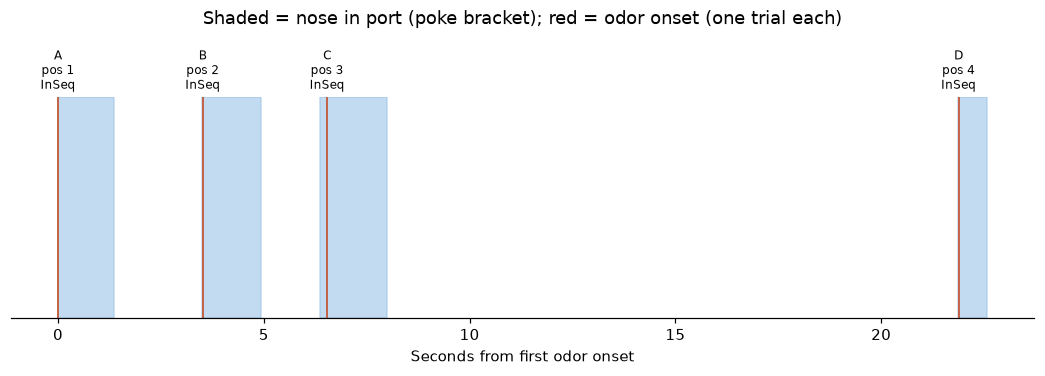

,split,segment,start,end,start_s,end_exclusive_s
0,train,0,0,1151067,0.010575,1151.077575
1,train,1,1151067,3678606,1334.488575,3862.027575
2,validation,1,3678606,3783096,3862.027575,3966.517575
3,validation,2,3783096,4466879,5887.579575,6571.362575
4,test,2,4466879,5255152,6571.362575,7359.635575


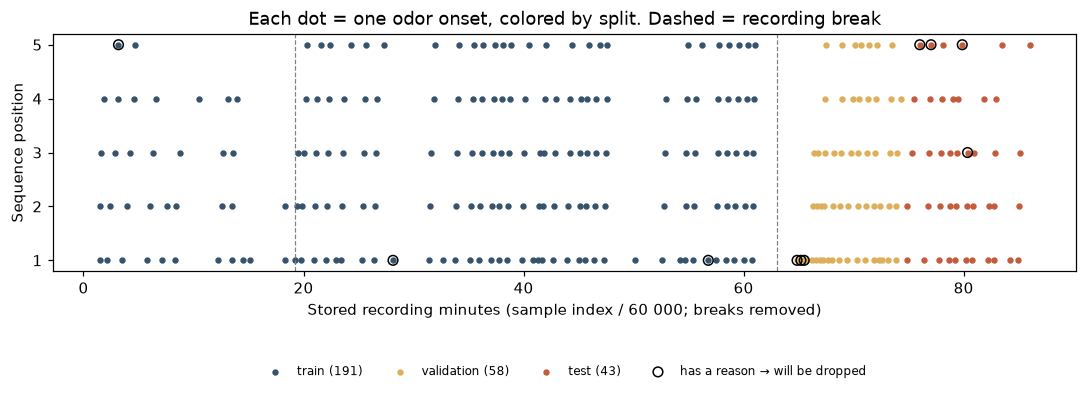

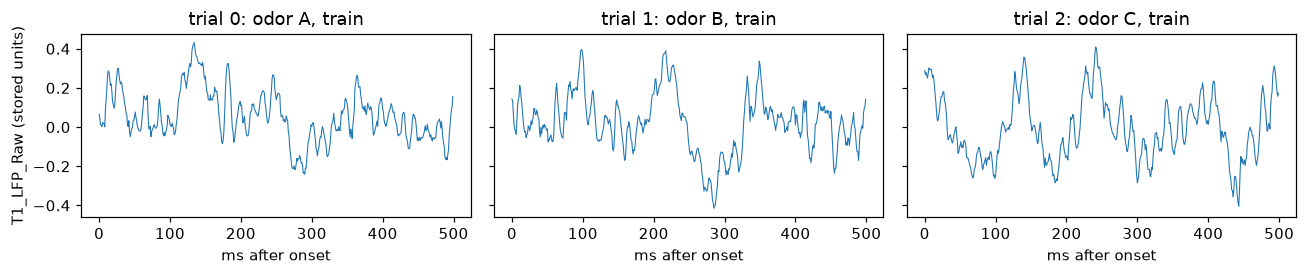

guard = 2199 samples (2199 ms) at each block edge
37 clean blocks, 32 bad spans, 68 bad samples


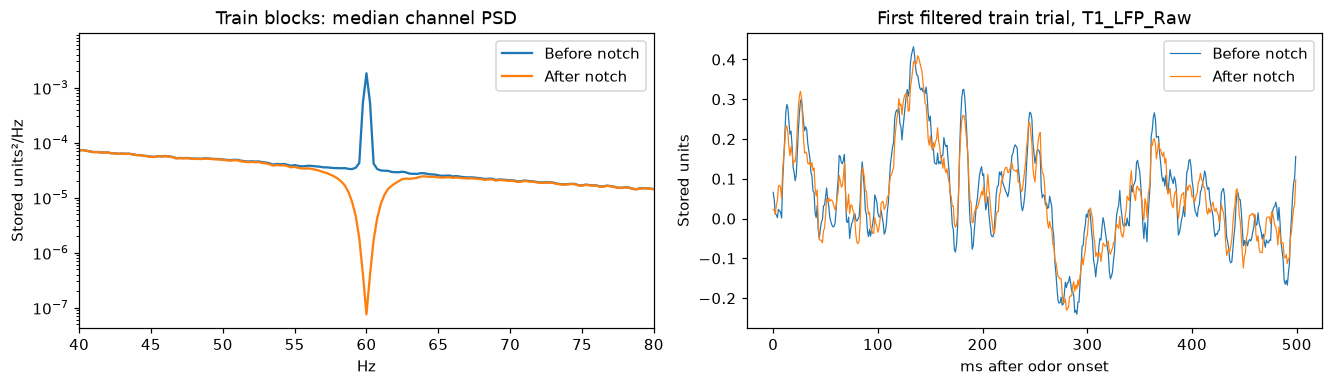

Exclusions: {'early_withdrawal': 10, 'out_of_sequence': 30, 'filter_edge': 3}


position,1,2,3,4,5
split,,,,,
train,47,37,31,30,22
validation,16,11,8,8,4
test,11,10,8,3,3


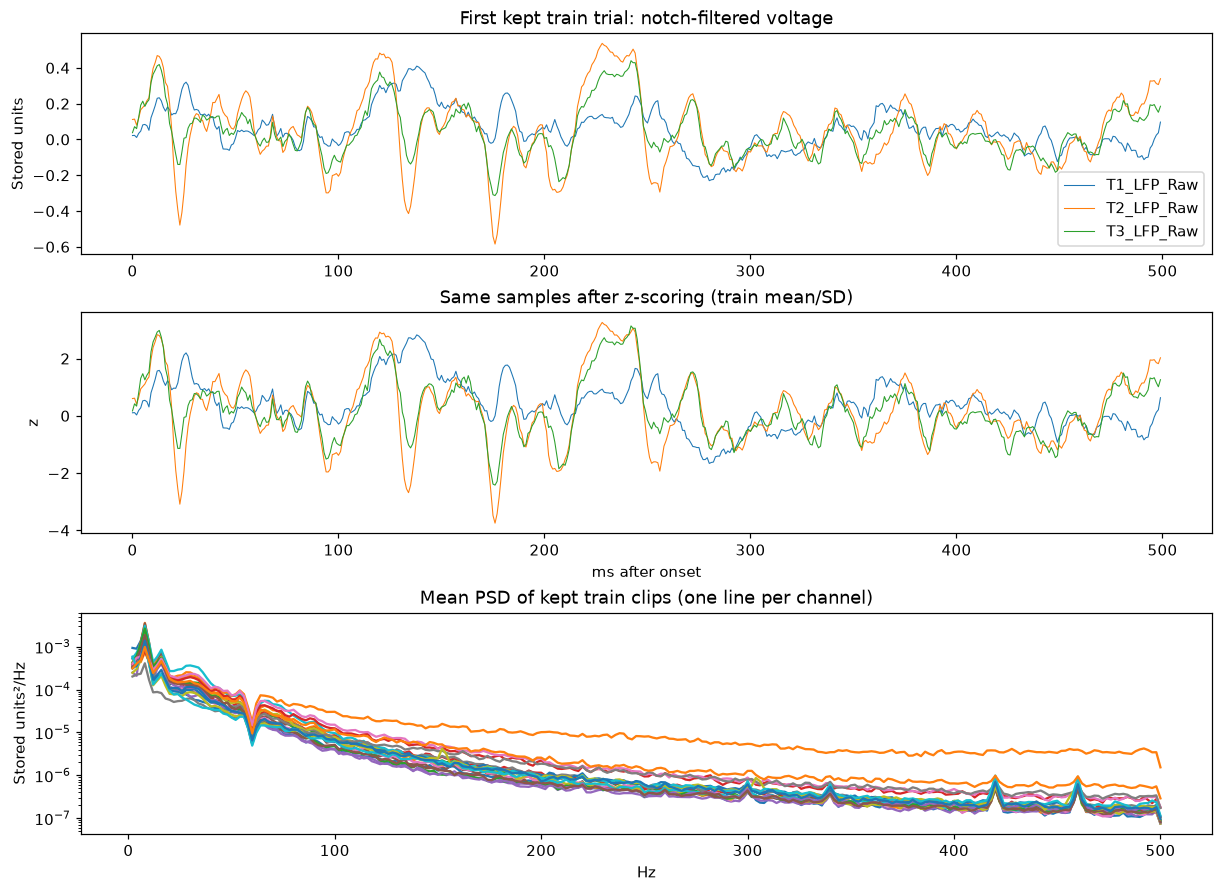

080718_mitt: 249 trials kept, 22/22 channels → /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/raw_lfp/080718_mitt


081106_barat: 154 trials kept, 22/22 channels → /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/raw_lfp/081106_barat


090212_stella: 190 trials kept, 21/21 channels → /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/raw_lfp/090212_stella


090212_superchris: 187 trials kept, 21/21 channels → /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/raw_lfp/090212_superchris


090420_buchanan: 208 trials kept, 20/20 channels → /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/raw_lfp/090420_buchanan


In [13]:
# Stop before processing anything if a previous run's output is already there
existing = [s for s in SESSIONS if (OUTPUT_ROOT / s).exists()]
if existing and not OVERWRITE:
    raise FileExistsError(f'Output already exists for {existing}; delete it or set OVERWRITE = True')

summaries = []
for session in SESSIONS:
    if session == EXAMPLE_SESSION:
        print(f'===== {session} (example: step-by-step plots below) =====')
    summaries.append(process_session(session, show=(session == EXAMPLE_SESSION)))

## Summary

In [14]:
rows_ = []
for s in summaries:
    with np.load(OUTPUT_ROOT / s['session'] / 'position_decoding.npz') as d:
        X_shape = d['X'].shape
    rows_.append(dict(rat=s['session'], inseq_onsets=s.get('raw_inseq_onsets'), kept=s['retained'],
                      train=s['after']['split'].get('train', 0),
                      validation=s['after']['split'].get('validation', 0),
                      test=s['after']['split'].get('test', 0),
                      channels=f"{s['channels_kept']}/{s['channels_total']}",
                      X_shape=X_shape))
summary_df = pd.DataFrame(rows_).set_index('rat')
display(summary_df)
print('Total kept trials:', summary_df['kept'].sum())

,inseq_onsets,kept,train,validation,test,channels,X_shape
rat,,,,,,,
080718_mitt,262,249,167,47,35,22/22,"(249, 500, 22)"
081106_barat,155,154,111,24,19,22/22,"(154, 500, 22)"
090212_stella,194,190,150,28,12,21/21,"(190, 500, 21)"
090212_superchris,210,187,138,31,18,21/21,"(187, 500, 21)"
090420_buchanan,226,208,174,19,15,20/20,"(208, 500, 20)"


Total kept trials: 988
